# **Module 08: Non-Parametric Tests**

---

## 📌 Overview

**Non-Parametric Tests** (also known as distribution-free tests) provide a robust alternative to classical parametric methods when data **do not meet strict assumptions**, such as normality of the distribution or homogeneity of variances. They are also the natural choice when working with **small sample sizes**, heavy presence of outliers, or variables measured on **ordinal and nominal scales**.

Instead of relying on parameters like the mean and standard deviation, many of these tests operate on **ranks**, medians, or frequencies. In this notebook, we will explore when to choose non-parametric approaches and how to apply them in practice using Python.

---

## 🎯 Learning Objectives

By the end of this module, you will be able to:

* **Identify when to use non-parametric tests** as an alternative to parametric tests (comparing advantages, limitations, and statistical power).
* **Compare two independent samples** using the **Mann-Whitney U test** (alternative to the independent $t$-test).
* **Compare two paired samples** using the **Wilcoxon signed-rank test** (alternative to the paired $t$-test).
* **Compare three or more groups** using the **Kruskal-Wallis test** (independent samples) and **Friedman test** (related samples / repeated measures), along with *post-hoc* analyses (such as Dunn's test).
* **Evaluate associations and goodness-of-fit in categorical data** using the **Chi-square ($\chi^2$)** and **Fisher's Exact** tests.
* **Implement and interpret non-parametric tests in Python** using `scipy.stats` and `statsmodels`.

---

## 🧭 Module Structure

1. **Parametric vs. Non-Parametric** — Assumptions, rank-based mechanics, robustness, and trade-offs.
2. **One-Sample and Goodness-of-Fit Tests** — Sign Test, Binomial Test, and Kolmogorov-Smirnov test.
3. **Two Independent and Paired Samples** — Mann-Whitney U Test and Wilcoxon Signed-Rank Test.
4. **Multiple Groups** — Kruskal-Wallis Test, Friedman Test, and multiple comparisons (*post-hoc*).
5. **Tests for Categorical Variables** — Chi-square ($\chi^2$) test of independence, Chi-square goodness-of-fit, and Fisher's Exact Test.
6. **Hands-on Python** — Complete practical application on real datasets using `scipy.stats`, `statsmodels`, `numpy`, `pandas`, and `seaborn`.

---

## 🛠️ Technical Requirements

* Prior knowledge of **Hypothesis Testing** (*Module 07*) and **Measurement Scales** (*Module 01*).
* Python environment configured with: `numpy`, `pandas`, `scipy`, `statsmodels`, `matplotlib`, and `seaborn`.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as st
import scipy.stats as stats
from scipy.stats import norm, chi2, binomtest, rankdata

from statsmodels.stats.contingency_tables import mcnemar, cochrans_q

Hypothesis tests are divided into parametric and non-parametric tests. In Module 07, we saw that `parametric tests` formulate hypotheses about population parameters ($\mu$, $\sigma$, $\sigma^2$, $p$) and require strict assumptions, such as normality and homogeneity of variances.

`Non-parametric tests` formulate hypotheses about qualitative characteristics of the population and can be applied to data on nominal or ordinal scales. Because they make few assumptions about the data distribution, they are also called `distribution-free tests`.

* Advantages: they do not require normality, can be applied to qualitative data, and involve simpler calculations.

* Disadvantages: converting quantitative data into qualitative forms (signs or ranks) results in a loss of information, and because they are less efficient, they require stronger evidence (larger samples or larger differences) to reject $H_0$.

`NOTE:` *Parametric tests are more powerful and should be preferred whenever their assumptions are met. Non-parametric tests are the alternative when assumptions are violated or when variables are qualitative.*

## **Classification of Non-Parametric Tests**

| Scope | Measurement Level | Test |
|---|---|---|
| One sample | Binary | Binomial |
| | Nominal or ordinal | $\chi^2$ |
| | Ordinal | Sign Test |
| Two paired samples | Binary | McNemar |
| | Ordinal | Sign Test and Wilcoxon |
| Two independent samples | Nominal or ordinal | $\chi^2$ |
| | Ordinal | Mann-Whitney U |
| $k$ paired samples | Binary | Cochran's Q |
| | Ordinal | Friedman |
| $k$ independent samples | Nominal or ordinal | $\chi^2$ |
| | Ordinal | Kruskal-Wallis |

Just as in Module 07, we will use a helper function for steps 5 and 6 (decision based on the p-value).

In [2]:
def decision(p_value, alpha):
    if p_value <= alpha:
        return f"P = {np.round(p_value, 4)} <= {alpha}: reject H0"
    return f"P = {np.round(p_value, 4)} > {alpha}: fail to reject H0"

And another helper function to plot the distribution of the test statistic showing the critical region (CR), the non-rejection region (NR), and the calculated value, just like the figures in the textbook.

In [3]:
def critical_region(distribution, critical_val, statistic, side="two-tailed", title="", x_label="Statistic"):

    # Chart range, including the calculated value
    start = min(distribution.ppf(0.0005), statistic - 0.5)
    end = max(distribution.ppf(0.9995), statistic + 0.5)
    x = np.linspace(start, end, 500)
    y = distribution.pdf(x)

    # Critical region according to the test type
    if side == "two-tailed":
        cr = (x <= -critical_val) | (x >= critical_val)
        marks = [-critical_val, critical_val]
    elif side == "left":
        cr = x <= critical_val
        marks = [critical_val]
    else:
        cr = x >= critical_val
        marks = [critical_val]

    plt.plot(x, y, color='black')
    plt.fill_between(x, y, where=cr, color='red', alpha=0.5, label='CR')
    plt.fill_between(x, y, where=~cr, color='gray', alpha=0.2, label='NR')

    for m in marks:
        plt.axvline(m, color='red', linestyle=':', linewidth=1)
        plt.text(m, 0.15 * y.max(), f' {np.round(m, 3)}', ha='left', color='red')

    plt.axvline(statistic, color='darkorange', linestyle='--', label=f'Calculated = {np.round(statistic, 3)}')
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel('Density')
    plt.legend()

    # Display the chart
    plt.show()

## **One-Sample Tests**

A random sample is drawn from the population and we test whether the data exhibit a specific characteristic or distribution.

### **Binomial Test**

Applied when the variable is binary: success ($X = 1$), with probability $p$, or failure ($X = 0$), with probability $q = 1 - p$.

$H_0: p = p_0$

$H_1: p \neq p_0$

The probability of obtaining $k$ successes in $N$ observations is:

$P[Y = k] = \binom{N}{k}\cdot p^k\cdot q^{N-k}$

In the test, we use the probability of values as extreme as or more extreme than the observed value, $P(Y \leq k) = \sum_{i=0}^{k}\binom{N}{i}\cdot p^i\cdot q^{N-i}$. For a two-tailed test, this value is doubled.

`Large samples` ($N > 25$): the distribution of $Y$ approximates the normal distribution, with continuity correction:

$Z_{cal} = \frac{|N\cdot\hat{p} - N\cdot p| - 0.5}{\sqrt{N\cdot p\cdot q}}$

#### Example 1

Eighteen students in an intensive English course chose between two teaching methods: 11 preferred Method 1 and 7 preferred Method 2. Is there a difference in preference ($\alpha = 5\%$)?

$H_0: p = q = 1/2$ and $H_1: p \neq q$

In [4]:
N = 18
k = 7  # Smaller observed frequency (Method 2)

# P(Y <= 7) summing binomial probabilities
p_one_tailed = sum(math.comb(N, i) * 0.5**i * 0.5**(N - i) for i in range(k + 1))

print(f"P(Y <= 7) = {np.round(p_one_tailed, 3)}")
print(f"Two-tailed P = {np.round(2 * p_one_tailed, 3)}")

P(Y <= 7) = 0.24
Two-tailed P = 0.481


In [5]:
# Verifying with scipy
result = binomtest(11, n=18, p=0.5, alternative='two-sided')
print(decision(result.pvalue, 0.05))

P = 0.4807 > 0.05: fail to reject H0


Note that the two-tailed p-value is 0.481, greater than 5%, so we fail to reject $H_0$: at a 95% confidence level, there is no difference in preference between the two methods.

#### Example 2

Same scenario with a larger sample: 30 students, with 18 choosing Method 1 and 12 choosing Method 2.

In [6]:
def binomial_z_test(successes, N, p=0.5):

    p_hat = successes / N
    z_cal = (abs(N * p_hat - N * p) - 0.5) / np.sqrt(N * p * (1 - p))
    p_value = 2 * (1 - norm.cdf(z_cal))  # Two-tailed

    return z_cal, p_value

z_cal, p_z = binomial_z_test(18, 30)

print(f"Calculated Z: {np.round(z_cal, 3)}")
print(decision(p_z, 0.05))

Calculated Z: 0.913
P = 0.3613 > 0.05: fail to reject H0


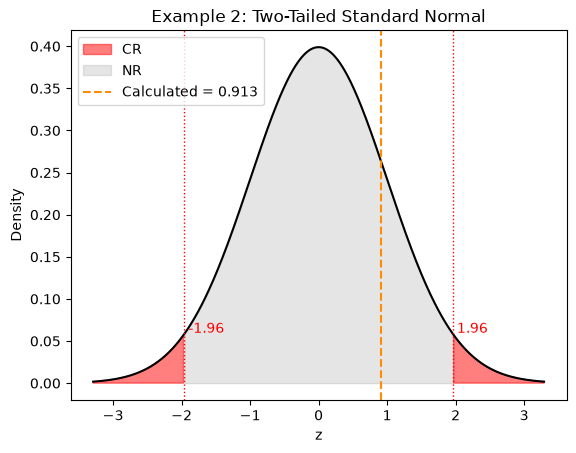

In [7]:
# Critical region for Example 2
critical_region(norm(), norm.ppf(0.975), z_cal, side="two-tailed",
                title='Example 2: Two-Tailed Standard Normal', x_label='z')

Note that $Z_{cal} = 0.913$ lies between $-1.96$ and $1.96$, so we fail to reject $H_0$: even with 30 students, there is no difference in preference between the methods.

`NOTE:` *The textbook reports P = 0.3524, but from the normal table the one-tailed probability of* $Z > 0.913$ *is 0.181, which gives P = 0.361 for the two-tailed test. The conclusion is the same.*

### **One-Sample Chi-Square ($\chi^2$) Test**

An extension of the binomial test for a variable with two or more categories (nominal or ordinal). It compares observed frequencies with expected frequencies.

$H_0:$ there is no significant difference between observed and expected frequencies

$H_1:$ there is a significant difference between observed and expected frequencies

$\chi^2_{cal} = \sum_{i=1}^{k}\frac{(O_i - E_i)^2}{E_i} \sim \chi^2_{k-1}$

We reject $H_0$ if $\chi^2_{cal} > \chi^2_c$.

#### Example 3

A homemade sweets shop wants to know whether brigadeiro sales vary by day of the week ($\alpha = 5\%$).

In [8]:
brigadeiros = pd.DataFrame({
    "Observed": [35, 24, 27, 32, 25, 36, 31],
    "Expected": [30, 30, 30, 30, 30, 30, 30]
}, index=["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"])

brigadeiros.T

,Sun,Mon,Tue,Wed,Thu,Fri,Sat
Observed,35,24,27,32,25,36,31
Expected,30,30,30,30,30,30,30


In [9]:
chi2_cal, p_chi2 = stats.chisquare(brigadeiros["Observed"], brigadeiros["Expected"])

print(f"Calculated Chi-square: {np.round(chi2_cal, 3)}")
print(f"Critical Chi-square (5%, 6 df): {np.round(chi2.ppf(0.95, 6), 3)}")
print(decision(p_chi2, 0.05))

Calculated Chi-square: 4.533
Critical Chi-square (5%, 6 df): 12.592
P = 0.6049 > 0.05: fail to reject H0


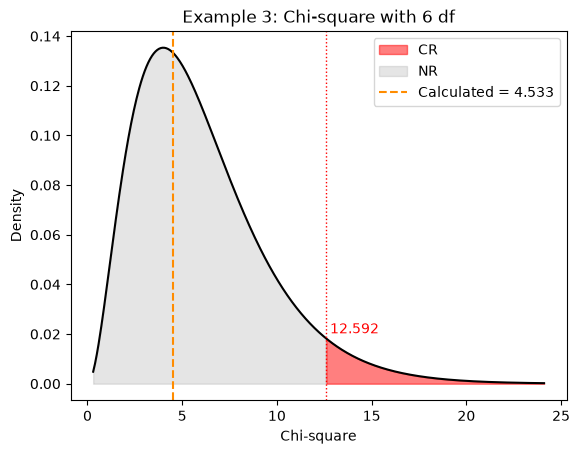

In [10]:
# Critical region for Example 3
critical_region(chi2(6), chi2.ppf(0.95, 6), chi2_cal, side="right",
                title='Example 3: Chi-square with 6 df', x_label='Chi-square')

Note that $\chi^2_{cal} = 4.533$ is smaller than $\chi^2_c = 12.592$, so we fail to reject $H_0$: at a 95% confidence level, brigadeiro sales do not vary by day of the week.

### **One-Sample Sign Test**

An alternative to the one-sample $t$-test when data are not normally distributed. The only requirement is that the variable be continuous. The test is based on the median $\tilde{\mu}$:

$H_0: \tilde{\mu} = \tilde{\mu}_0$

$H_1: \tilde{\mu} \neq \tilde{\mu}_0$

Essentially, each value above $\tilde{\mu}_0$ receives a (+) sign and each value below receives a (−) sign, while ties are excluded. Under $H_0$, both signs are equally likely ($p = 1/2$).

* `Small samples` ($N \leq 25$): binomial test with $p = 1/2$, where $k$ is the smaller sign frequency.
* `Large samples` ($N > 25$): $Z = \frac{(X \pm 0.5) - N/2}{0.5\cdot\sqrt{N}}$, using $X + 0.5$ if $X$ is the smaller frequency and $X - 0.5$ if it is the larger.

`NOTE:` *Because only the sign is used, this test discards considerable information and has low statistical power.*

#### Example 4

The median retirement age in a city is estimated to be 65 years. A sample of 20 retirees was collected ($\alpha = 10\%$).

In [11]:
retirement_age = np.array([59, 62, 66, 37, 60, 64, 66, 70, 72, 61,
                           64, 66, 68, 72, 78, 93, 79, 65, 67, 59])
median_0 = 65

positives = np.sum(retirement_age > median_0)
negatives = np.sum(retirement_age < median_0)
N = positives + negatives  # Ties excluded

print(f"(+) signs: {positives} | (-) signs: {negatives} | N = {N}")

result = binomtest(min(positives, negatives), n=N, p=0.5)
print(decision(result.pvalue, 0.10))

(+) signs: 11 | (-) signs: 8 | N = 19
P = 0.6476 > 0.1: fail to reject H0


Note that there are 11 (+) signs, 8 (−) signs, and one excluded tie ($N = 19$). The two-tailed p-value is 0.648, greater than 10%, so we fail to reject $H_0$: at a 90% confidence level, the median retirement age is 65 years.

## **Tests for Two Paired Samples**

Check whether two related samples differ, such as before-and-after measurements of an event. We use McNemar's test for binary variables and the Sign Test and Wilcoxon test for ordinal variables.

### **McNemar's Test**

Tests whether there are significant changes before and after an event for a binary variable, using a 2 x 2 contingency table:

| Before \ After | + | − |
|---|---|---|
| **+** | A | B |
| **−** | C | D |

`B` and `C` count those who changed their response. Under the null hypothesis, changes in either direction are equally likely:

$H_0: P(B) = P(C)$

$H_1: P(B) \neq P(C)$

$\chi^2_{cal} = \frac{(B - C)^2}{B + C}$, or, with continuity correction, $\chi^2_{cal} = \frac{(|B - C| - 1)^2}{B + C}$, both with 1 degree of freedom.

#### Example 5

Sixty workers indicated whether they preferred working in a private or public institution, before and after a civil service pension reform ($\alpha = 5\%$).

In [12]:
reform = pd.DataFrame([[22, 3],
                       [21, 14]],
                      index=["Before: Private", "Before: Public"],
                      columns=["After: Private", "After: Public"])
reform

,After: Private,After: Public
Before: Private,22,3
Before: Public,21,14


In [13]:
B = reform.iloc[0, 1]  # Private -> Public
C = reform.iloc[1, 0]  # Public -> Private

chi2_uncorrected = (B - C)**2 / (B + C)
chi2_corrected = (abs(B - C) - 1)**2 / (B + C)

print(f"Chi-square without correction: {np.round(chi2_uncorrected, 3)}")
print(f"Chi-square with correction: {np.round(chi2_corrected, 3)}")
print(f"Critical Chi-square (5%, 1 df): {np.round(chi2.ppf(0.95, 1), 3)}")

Chi-square without correction: 13.5
Chi-square with correction: 12.042
Critical Chi-square (5%, 1 df): 3.841


In [14]:
# Verifying with statsmodels
result = mcnemar(reform.values, exact=False, correction=True)
print(decision(result.pvalue, 0.05))

P = 0.0005 <= 0.05: reject H0


Note that $\chi^2_{cal} = 12.042$ (13.5 without correction) is greater than $\chi^2_c = 3.841$, so we reject $H_0$: at a 95% confidence level, the reform changed workers' preference. Of the 24 people who changed their opinion, 21 switched from public to private institutions.

### **Sign Test for Two Paired Samples**

An alternative to the paired $t$-test when data are not normally distributed. The sign of each pair is given by the difference between the values, and ties are excluded. Under the null hypothesis, the median of the differences is zero—that is, the number of (+) signs equals the number of (−) signs:

$H_0: \tilde{\mu}_d = 0$

$H_1: \tilde{\mu}_d \neq 0$

The calculation is identical to the one-sample sign test (binomial for $N \leq 25$ and normal approximation for $N > 25$).

#### Example 6

Productivity (parts per hour) of 30 workers before and after a training program ($\alpha = 5\%$).

In [15]:
productivity = pd.DataFrame({
    "Before": [36, 39, 27, 41, 40, 44, 38, 42, 40, 43, 37, 41, 38, 45, 40,
               39, 38, 39, 41, 36, 38, 40, 36, 40, 40, 38, 37, 40, 38, 40],
    "After": [40, 41, 29, 45, 39, 42, 39, 40, 42, 45, 35, 40, 38, 43, 40,
              42, 41, 39, 40, 38, 36, 38, 35, 42, 41, 40, 39, 42, 36, 40]
})

difference = productivity["After"] - productivity["Before"]
positives = np.sum(difference > 0)
negatives = np.sum(difference < 0)
N = positives + negatives

print(f"(+) signs: {positives} | (-) signs: {negatives} | Ties: {len(difference) - N} | N = {N}")

(+) signs: 15 | (-) signs: 11 | Ties: 4 | N = 26


In [16]:
def sign_test_z(positives, negatives):

    N = positives + negatives
    x = min(positives, negatives)  # Smaller frequency: use X + 0.5

    z_cal = ((x + 0.5) - N / 2) / (0.5 * np.sqrt(N))
    p_value = 2 * norm.cdf(z_cal)  # Two-tailed

    return z_cal, p_value

z_cal, p_z = sign_test_z(positives, negatives)

print(f"Calculated Z: {np.round(z_cal, 3)}")
print(decision(p_z, 0.05))

Calculated Z: -0.588
P = 0.5563 > 0.05: fail to reject H0


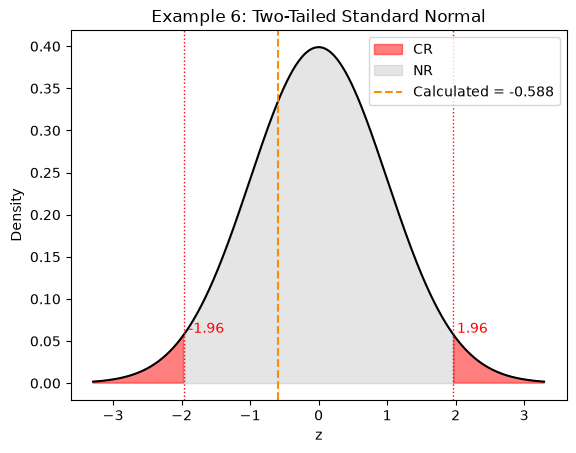

In [17]:
# Critical region for Example 6
critical_region(norm(), norm.ppf(0.975), z_cal, side="two-tailed",
                title='Example 6: Two-Tailed Standard Normal', x_label='z')

Note that $Z_{cal} = -0.588$ lies between $-1.96$ and $1.96$ and the p-value is 0.556, so we fail to reject $H_0$: at a 95% confidence level, the training did not change productivity.

`NOTE:` *In step 6 of the p-value solution, the textbook prints "since P > 0.05, we reject the null hypothesis", which is a typo—the correct decision is to fail to reject, matching the critical value solution.*

### **Wilcoxon Signed-Rank Test**

A more powerful extension of the sign test: in addition to direction, it considers the magnitude of the differences between pairs.

Procedure:
1. Compute the difference $d_i$ for each pair and exclude pairs where $d_i = 0$.
2. Order $|d_i|$ and assign ranks (tied differences receive the average rank).
3. Attach the sign of $d_i$ to each rank and sum the positive ranks ($S_p$) and negative ranks ($S_n$).

$H_0: \tilde{\mu}_d = 0$

$H_1: \tilde{\mu}_d \neq 0$

For $N > 15$, we use the normal approximation with tie correction:

$Z_{cal} = \frac{\min(S_p, S_n) - \frac{N\cdot(N+1)}{4}}{\sqrt{\frac{N\cdot(N+1)\cdot(2N+1)}{24} - \frac{\sum_{j=1}^{g}t_j^3 - \sum_{j=1}^{g}t_j}{48}}}$

where $g$ is the number of tied rank groups and $t_j$ is the number of tied observations in group $j$.

#### Example 7

Scores of 18 students on an English proficiency exam before and after a 6-month intensive course ($\alpha = 5\%$).

In [18]:
scores = pd.DataFrame({
    "Before": [56, 65, 70, 78, 47, 52, 64, 70, 72, 78, 80, 26, 55, 60, 71, 66, 60, 17],
    "After": [60, 62, 74, 79, 53, 59, 65, 75, 75, 88, 78, 26, 63, 59, 71, 75, 71, 24]
})

def wilcoxon(before, after):

    d = np.array(after) - np.array(before)
    d = d[d != 0]  # Exclude ties
    N = len(d)

    # Ranks of absolute values (average rank for ties)
    ranks = rankdata(np.abs(d))
    s_p = ranks[d > 0].sum()
    s_n = ranks[d < 0].sum()

    # Tie correction
    _, t = np.unique(np.abs(d), return_counts=True)
    correction = (np.sum(t**3) - np.sum(t)) / 48

    z_cal = (min(s_p, s_n) - N * (N + 1) / 4) / np.sqrt(N * (N + 1) * (2 * N + 1) / 24 - correction)
    p_value = 2 * norm.cdf(z_cal)  # Two-tailed

    return s_p, s_n, z_cal, p_value

s_p, s_n, z_cal, p_w = wilcoxon(scores["Before"], scores["After"])

print(f"Sp = {s_p} | Sn = {s_n}")
print(f"Calculated Z: {np.round(z_cal, 3)}")
print(decision(p_w, 0.05))

Sp = 124.5 | Sn = 11.5
Calculated Z: -2.925
P = 0.0034 <= 0.05: reject H0


In [19]:
# Verifying with scipy (normal approximation, without continuity correction)
stats.wilcoxon(scores["Before"], scores["After"], zero_method='wilcox', correction=False, method='approx')

WilcoxonResult(statistic=np.float64(11.5), pvalue=np.float64(0.0034449049423722184))

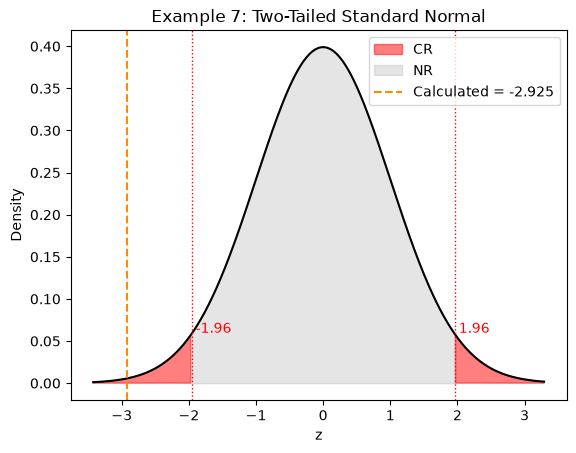

In [20]:
# Critical region for Example 7
critical_region(norm(), norm.ppf(0.975), z_cal, side="two-tailed",
                title='Example 7: Two-Tailed Standard Normal', x_label='z')

Note that $S_p = 124.5$, $S_n = 11.5$, and $Z_{cal} = -2.925$, which falls in the critical region ($Z_{cal} < -1.96$). Since the p-value is 0.0034, we reject $H_0$: at a 95% confidence level, the course changed students' performance, and since nearly all differences are positive, scores improved.

## **Tests for Two Independent Samples**

Compare two populations based on independent samples, which do not need to have the same size.

### **Chi-Square ($\chi^2$) Test for Two Independent Samples**

The same test from Module 03: compares the observed frequencies in each cell of a contingency table with the expected frequencies under the hypothesis of no association.

$\chi^2_{cal} = \sum_{i=1}^{I}\sum_{j=1}^{J}\frac{(O_{ij} - E_{ij})^2}{E_{ij}} \sim \chi^2_{(I-1)\cdot(J-1)}$

#### Example 8

Satisfaction of 200 customers across three health insurance providers, the same example from Module 03 ($\alpha = 5\%$).

In [21]:
health_plan = pd.DataFrame([[40, 16, 12],
                            [32, 24, 16],
                            [24, 32, 4]],
                           index=["Total Health", "Viva Vida", "Mena Saúde"],
                           columns=["Low", "Medium", "High"])

chi2_cal, p_chi2, df, expected = stats.chi2_contingency(health_plan)

print(f"Calculated Chi-square: {np.round(chi2_cal, 3)} ({df} df)")
print(f"Critical Chi-square (5%): {np.round(chi2.ppf(0.95, df), 3)}")
print(decision(p_chi2, 0.05))

pd.DataFrame(expected, index=health_plan.index, columns=health_plan.columns).round(1)

Calculated Chi-square: 15.861 (4 df)
Critical Chi-square (5%): 9.488
P = 0.0032 <= 0.05: reject H0


,Low,Medium,High
Total Health,32.6,24.5,10.9
Viva Vida,34.6,25.9,11.5
Mena Saúde,28.8,21.6,9.6


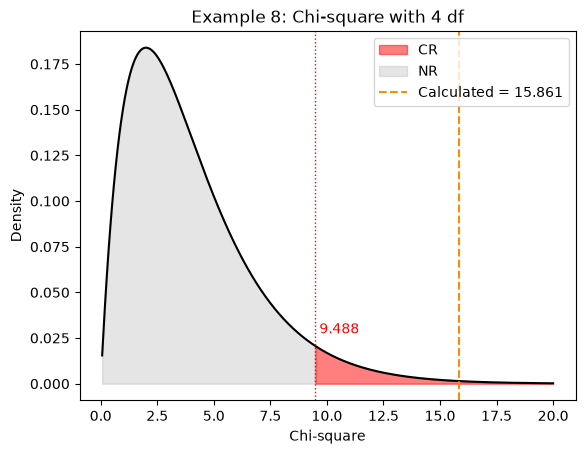

In [22]:
# Critical region for Example 8
critical_region(chi2(4), chi2.ppf(0.95, 4), chi2_cal, side="right",
                title='Example 8: Chi-square with 4 df', x_label='Chi-square')

Note that $\chi^2_{cal} = 15.861$ is greater than $\chi^2_c = 9.488$, so we reject $H_0$: at a 95% confidence level, there is an association between the provider and the satisfaction level. The table above shows the expected frequencies if there were no association.

### **Mann-Whitney U Test**

One of the most powerful non-parametric tests, serving as the non-parametric counterpart to the independent two-sample $t$-test. It tests the equality of medians:

$H_0: \tilde{\mu}_1 = \tilde{\mu}_2$

$H_1: \tilde{\mu}_1 \neq \tilde{\mu}_2$

Procedure:
1. Combine both samples ($N = N_1 + N_2$), where $N_1$ is the smaller sample, and assign ranks from 1 to $N$ (ties receive the average rank).
2. Sum the ranks for each sample ($R_1$ and $R_2$).
3. Compute $U_1 = N_1\cdot N_2 + \frac{N_1\cdot(N_1+1)}{2} - R_1$ and $U_2 = N_1\cdot N_2 + \frac{N_2\cdot(N_2+1)}{2} - R_2$.
4. The test statistic is $U_{cal} = \min(U_1, U_2)$, and we reject $H_0$ if $U_{cal} < U_c$ (Table J in the textbook).

`Large samples` ($N_2 > 20$):

$Z_{cal} = \frac{U - \frac{N_1\cdot N_2}{2}}{\sqrt{\frac{N_1\cdot N_2}{N\cdot(N-1)}\cdot\left(\frac{N^3 - N}{12} - \frac{\sum_{j=1}^{g}t_j^3 - \sum_{j=1}^{g}t_j}{12}\right)}}$

#### Example 9

Diameter (mm) of parts produced by two machines. Do the two samples come from populations with equal medians ($\alpha = 5\%$)?

In [23]:
machine_a = [48.50, 48.65, 48.58, 48.55, 48.66, 48.64, 48.50, 48.72]
machine_b = [48.75, 48.64, 48.80, 48.85, 48.78, 48.79, 49.20]

# Normality of samples
for name, machine in [("Machine A", machine_a), ("Machine B", machine_b)]:
    _, p_normal = stats.shapiro(machine)
    print(f"Shapiro-Wilk {name}: {decision(p_normal, 0.05)}")

Shapiro-Wilk Machine A: P = 0.5202 > 0.05: fail to reject H0
Shapiro-Wilk Machine B: P = 0.0325 <= 0.05: reject H0


In [24]:
def mann_whitney(sample_1, sample_2):

    # sample_1 should be the smaller sample
    n1, n2 = len(sample_1), len(sample_2)
    N = n1 + n2

    ranks = rankdata(np.concatenate([sample_1, sample_2]))
    r1 = ranks[:n1].sum()
    r2 = ranks[n1:].sum()

    u1 = n1 * n2 + n1 * (n1 + 1) / 2 - r1
    u2 = n1 * n2 + n2 * (n2 + 1) / 2 - r2
    u_cal = min(u1, u2)

    # Normal approximation with tie correction
    _, t = np.unique(ranks, return_counts=True)
    variance = (n1 * n2 / (N * (N - 1))) * ((N**3 - N) / 12 - (np.sum(t**3) - np.sum(t)) / 12)
    z_cal = (u_cal - n1 * n2 / 2) / np.sqrt(variance)

    return r1, r2, u_cal, z_cal

r1, r2, u_cal, z_cal = mann_whitney(machine_b, machine_a)

print(f"R1 (Machine B) = {r1} | R2 (Machine A) = {r2}")
print(f"Calculated U: {u_cal}")

R1 (Machine B) = 80.5 | R2 (Machine A) = 39.5
Calculated U: 3.5


Note that Machine B does not follow a normal distribution, so we use the Mann-Whitney test. Since $U_{cal} = 3.5$ is smaller than $U_c = 10$ ($N_1 = 7$, $N_2 = 8$, two-tailed test at $\alpha = 5\%$, Table J in the textbook), we reject $H_0$: at a 95% confidence level, the median diameters of parts from the two machines differ.

#### Example 10

Even with a small sample, what would the result be using the normal approximation?

In [25]:
print(f"Calculated Z: {np.round(z_cal, 3)}")
print(decision(2 * norm.cdf(z_cal), 0.05))

Calculated Z: -2.84
P = 0.0045 <= 0.05: reject H0


In [26]:
# Verifying with scipy
stats.mannwhitneyu(machine_b, machine_a, use_continuity=False, method='asymptotic')

MannwhitneyuResult(statistic=np.float64(52.5), pvalue=np.float64(0.004505689306881697))

Note that $Z_{cal} = -2.840$ is less than $-1.96$ and the p-value is 0.0045, so the normal approximation leads to the same conclusion: the medians of the two machines differ.

`NOTE:` *SciPy reports* $U = 52.5$*, which is* $U_1$ *for the first sample passed to the function. Since* $U_1 + U_2 = N_1\cdot N_2$*, the p-value is identical.*

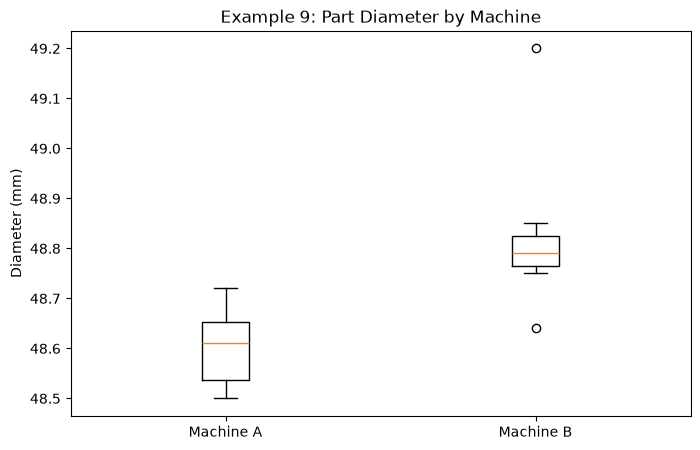

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([machine_a, machine_b])
ax.set_xticks([1, 2], ["Machine A", "Machine B"])
ax.set_ylabel('Diameter (mm)')
ax.set_title('Example 9: Part Diameter by Machine')

# Display the chart
plt.show()

## **Tests for k Paired Samples**

Evaluate whether $k \geq 3$ paired samples were drawn from the same population. We use Cochran's Q test for binary variables and the Friedman test for ordinal variables.

### **Cochran's Q Test**

An extension of McNemar's test to $k$ related groups with binary data. Data are arranged in a table with $N$ rows (cases) and $k$ columns (groups or conditions).

$H_0: p_1 = p_2 = \cdots = p_k$

$H_1: \exists_{(i,j)}\ p_i \neq p_j,\ i \neq j$

$Q_{cal} = \frac{k\cdot(k-1)\cdot\sum_{j=1}^{k}(G_j - \overline{G})^2}{k\cdot\sum_{i=1}^{N}L_i - \sum_{i=1}^{N}L_i^2} \sim \chi^2_{k-1}$

where $G_j$ is the total number of successes in column $j$, $\overline{G}$ is the mean of $G_j$, and $L_i$ is the total number of successes in row $i$.

#### Example 11

Twenty consumers rated three supermarkets as satisfactory (1) or not (0). Is the proportion of positive ratings the same across all three ($\alpha = 10\%$)?

In [28]:
supermarkets = pd.DataFrame({
    "A": [1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0],
    "B": [1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0],
    "C": [1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
})

def cochran_q(data):

    k = data.shape[1]
    G = data.sum(axis=0)  # Successes per column
    L = data.sum(axis=1)  # Successes per row

    q_cal = k * (k - 1) * np.sum((G - G.mean())**2) / (k * L.sum() - np.sum(L**2))
    p_value = 1 - chi2.cdf(q_cal, k - 1)

    return q_cal, p_value

q_cal, p_q = cochran_q(supermarkets)

print(f"Successes per supermarket: {supermarkets.sum().to_dict()}")
print(f"Calculated Q: {np.round(q_cal, 3)}")
print(f"Critical Chi-square (10%, 2 df): {np.round(chi2.ppf(0.90, 2), 3)}")
print(decision(p_q, 0.10))

Successes per supermarket: {'A': 11, 'B': 11, 'C': 16}
Calculated Q: 4.167
Critical Chi-square (10%, 2 df): 4.605
P = 0.1245 > 0.1: fail to reject H0


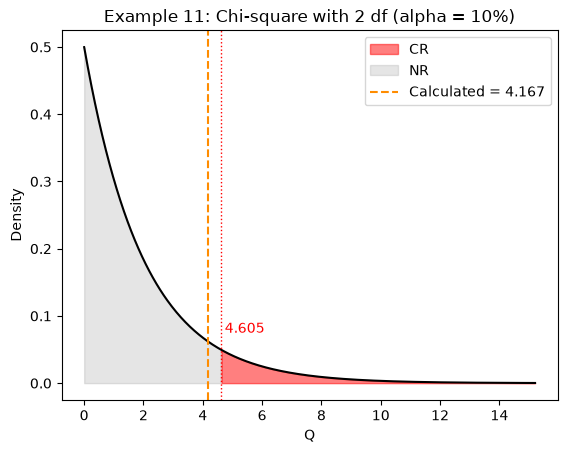

In [29]:
# Critical region for Example 11
critical_region(chi2(2), chi2.ppf(0.90, 2), q_cal, side="right",
                title='Example 11: Chi-square with 2 df (alpha = 10%)', x_label='Q')

In [30]:
# Verifying with statsmodels
result = cochrans_q(supermarkets.values)
print(f"Q = {np.round(result.statistic, 3)} | P = {np.round(result.pvalue, 4)}")

Q = 4.167 | P = 0.1245


Note that $Q_{cal} = 4.167$ is smaller than $\chi^2_c = 4.605$, so we fail to reject $H_0$: at a 90% confidence level, the proportion of satisfied customers is the same across the three supermarkets.

### **Friedman Test**

An extension of the Wilcoxon test to $k \geq 3$ paired samples, and an alternative to ANOVA when normality and homogeneity of variances are violated.

$H_0: \tilde{\mu}_1 = \tilde{\mu}_2 = \cdots = \tilde{\mu}_k$

$H_1: \exists_{(i,j)}\ \tilde{\mu}_i \neq \tilde{\mu}_j,\ i \neq j$

We assign ranks from 1 to $k$ within each row and sum the ranks of each column ($R_j$):

$F_{r,cal} = \frac{12}{N\cdot k\cdot(k+1)}\cdot\sum_{j=1}^{k}R_j^2 - 3\cdot N\cdot(k+1)$

When ties occur within rows, the statistic is corrected:

$F'_{r,cal} = \frac{12\cdot\sum_{j=1}^{k}R_j^2 - 3\cdot N^2\cdot k\cdot(k+1)^2}{N\cdot k\cdot(k+1) + \frac{N\cdot k - \sum_{i=1}^{N}\sum_{j=1}^{g_i}t_{ij}^3}{k-1}}$

For large $N$ and $k$, $F_r \sim \chi^2_{k-1}$.

#### Example 12

Weight of 15 patients before treatment (BT), post-treatment (PT), and three months later (A3M). Is the treatment effective ($\alpha = 5\%$)?

In [31]:
weights = pd.DataFrame({
    "BT": [65, 89, 96, 90, 70, 72, 87, 74, 66, 135, 82, 76, 94, 80, 73],
    "PT": [62, 85, 95, 84, 70, 65, 84, 74, 64, 132, 75, 73, 90, 80, 70],
    "A3M": [58, 80, 95, 79, 66, 62, 77, 69, 62, 132, 71, 67, 88, 77, 68]
})

# Ranks within each row
ranks = weights.rank(axis=1)
print(f"Sum of ranks: {ranks.sum().to_dict()}")
print(f"Mean rank: {ranks.mean().round(3).to_dict()}")

Sum of ranks: {'BT': 43.5, 'PT': 30.5, 'A3M': 16.0}
Mean rank: {'BT': 2.9, 'PT': 2.033, 'A3M': 1.067}


In [32]:
def friedman(data):

    N, k = data.shape
    ranks = data.rank(axis=1)
    R = ranks.sum(axis=0)

    # Uncorrected
    f_r = 12 / (N * k * (k + 1)) * np.sum(R**2) - 3 * N * (k + 1)

    # Corrected for ties within rows
    sum_t3 = sum(np.sum(np.unique(row, return_counts=True)[1]**3) for row in data.values)
    f_r_corrected = (12 * np.sum(R**2) - 3 * N**2 * k * (k + 1)**2) / (N * k * (k + 1) + (N * k - sum_t3) / (k - 1))

    return f_r, f_r_corrected

f_r, f_r_corrected = friedman(weights)

print(f"Friedman without correction: {np.round(f_r, 3)}")
print(f"Friedman with correction: {np.round(f_r_corrected, 3)}")
print(f"Critical Chi-square (5%, 2 df): {np.round(chi2.ppf(0.95, 2), 3)}")

Friedman without correction: 25.233
Friedman with correction: 27.527
Critical Chi-square (5%, 2 df): 5.991


In [33]:
# Verifying with scipy (automatically applies tie correction)
stats.friedmanchisquare(weights["BT"], weights["PT"], weights["A3M"])

FriedmanchisquareResult(statistic=np.float64(27.527272727272713), pvalue=np.float64(1.0532432302056965e-06))

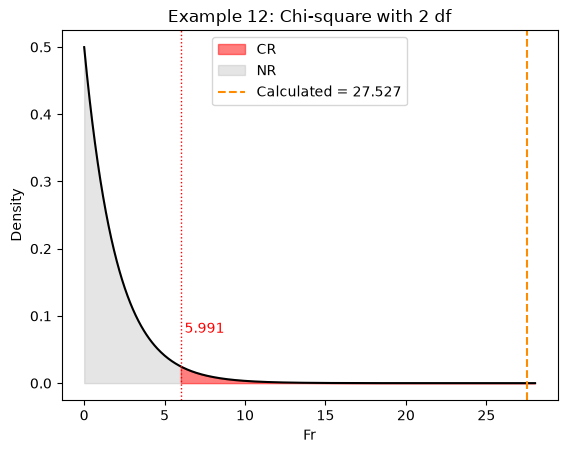

In [34]:
# Critical region for Example 12
critical_region(chi2(2), chi2.ppf(0.95, 2), f_r_corrected, side="right",
                title='Example 12: Chi-square with 2 df', x_label='Fr')

Note that $F'_{r,cal} = 27.527$ (25.233 without correction) is much greater than $\chi^2_c = 5.991$, so we reject $H_0$: at a 95% confidence level, the treatment is effective. The mean rank drops from 2.9 (before) to 1.07 (three months later), meaning weight decreased.

## **Tests for k Independent Samples**

Evaluate whether $k \geq 3$ independent samples come from the same population. We use the $\chi^2$ test for nominal or ordinal variables and the Kruskal-Wallis test for ordinal variables.

### **Chi-Square ($\chi^2$) Test for k Independent Samples**

A direct extension of the two-sample test. The rows of the contingency table represent the categories of the variable, and the columns represent the groups.

$H_0:$ there is no significant difference among the $k$ groups

$H_1:$ there is a significant difference among the $k$ groups

#### Example 13

Productivity (low, medium, high) of employees at a company across each of four work shifts ($\alpha = 5\%$).

In [35]:
shifts = pd.DataFrame([[50, 60, 40, 50],
                       [80, 90, 80, 80],
                       [270, 200, 180, 170]],
                      index=["Low", "Medium", "High"],
                      columns=["Shift 1", "Shift 2", "Shift 3", "Shift 4"])

chi2_cal, p_chi2, df, expected = stats.chi2_contingency(shifts)

print(f"Calculated Chi-square: {np.round(chi2_cal, 3)} ({df} df)")
print(f"Critical Chi-square (5%): {np.round(chi2.ppf(0.95, df), 3)}")
print(decision(p_chi2, 0.05))

Calculated Chi-square: 13.143 (6 df)
Critical Chi-square (5%): 12.592
P = 0.0408 <= 0.05: reject H0


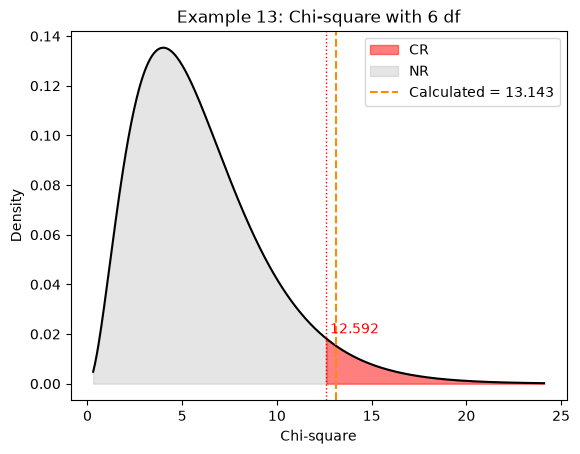

In [36]:
# Critical region for Example 13
critical_region(chi2(6), chi2.ppf(0.95, 6), chi2_cal, side="right",
                title='Example 13: Chi-square with 6 df', x_label='Chi-square')

Note that $\chi^2_{cal} = 13.143$ is greater than $\chi^2_c = 12.592$ and the p-value is 0.041, so we reject $H_0$: at a 95% confidence level, productivity varies by shift. Shift 1, for example, has more high-productivity employees than expected (270 vs. 243).

### **Kruskal-Wallis Test**

Checks whether $k > 2$ independent samples come from the same population. It is the alternative to ANOVA when normality and homogeneity of variances are violated, when the sample is small, or when the variable is ordinal. For $k = 2$, it is equivalent to the Mann-Whitney test.

$H_0: \tilde{\mu}_1 = \tilde{\mu}_2 = \cdots = \tilde{\mu}_k$

$H_1: \exists_{(i,j)}\ \tilde{\mu}_i \neq \tilde{\mu}_j,\ i \neq j$

All $N$ observations are ranked from 1 to $N$, and we sum the ranks for each group ($R_j$):

$H_{cal} = \frac{12}{N\cdot(N+1)}\cdot\sum_{j=1}^{k}\frac{R_j^2}{n_j} - 3\cdot(N+1)$

With ties: $H'_{cal} = \frac{H_{cal}}{1 - \frac{\sum_{j=1}^{g}(t_j^3 - t_j)}{N^3 - N}}$

If $k = 3$ and all $n_j \leq 5$, we use Table L in the textbook; otherwise, $H \sim \chi^2_{k-1}$.

#### Example 14

Stress levels of 36 patients after three different treatments, 12 in each ($\alpha = 1\%$).

In [37]:
stress = pd.DataFrame({
    "A": [6, 5, 4, 5, 3, 4, 5, 2, 4, 3, 5, 2],
    "B": [6, 7, 5, 8, 7, 8, 6, 9, 8, 6, 8, 8],
    "C": [5, 9, 8, 7, 9, 11, 7, 8, 9, 10, 7, 8]
})

def kruskal_wallis(*groups):

    n = np.array([len(g) for g in groups])
    N = n.sum()
    ranks = rankdata(np.concatenate(groups))

    # Sum of ranks for each group
    splits = np.cumsum(n)[:-1]
    R = np.array([p.sum() for p in np.split(ranks, splits)])

    h_cal = 12 / (N * (N + 1)) * np.sum(R**2 / n) - 3 * (N + 1)

    # Tie correction
    _, t = np.unique(ranks, return_counts=True)
    h_corrected = h_cal / (1 - np.sum(t**3 - t) / (N**3 - N))

    return R, h_cal, h_corrected

R, h_cal, h_corrected = kruskal_wallis(stress["A"], stress["B"], stress["C"])

print(f"Sum of ranks: {R}")
print(f"Calculated H: {np.round(h_cal, 3)}")
print(f"Corrected H: {np.round(h_corrected, 3)}")
print(f"Critical Chi-square (1%, 2 df): {np.round(chi2.ppf(0.99, 2), 3)}")

Sum of ranks: [ 85.5 262.  318.5]
Calculated H: 22.181
Corrected H: 22.662
Critical Chi-square (1%, 2 df): 9.21


In [38]:
# Verifying with scipy (automatically applies tie correction)
stats.kruskal(stress["A"], stress["B"], stress["C"])

KruskalResult(statistic=np.float64(22.66179048871358), pvalue=np.float64(1.1996504475044963e-05))

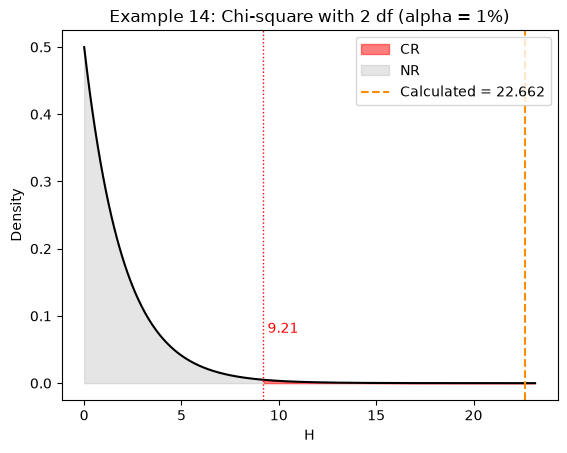

In [39]:
# Critical region for Example 14
critical_region(chi2(2), chi2.ppf(0.99, 2), h_corrected, side="right",
                title='Example 14: Chi-square with 2 df (alpha = 1%)', x_label='H')

Note that $H'_{cal} = 22.662$ (22.181 without correction) is greater than $\chi^2_c = 9.210$, so we reject $H_0$: at a 99% confidence level, the treatments lead to different stress levels. Treatment A has the lowest sum of ranks (85.5), meaning the lowest stress levels.

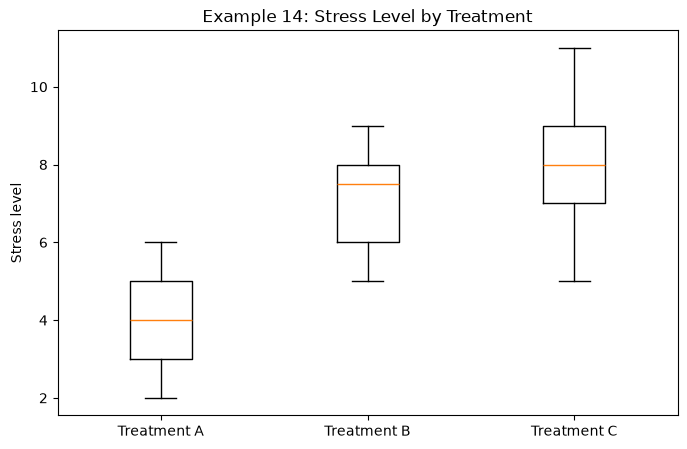

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([stress["A"], stress["B"], stress["C"]])
ax.set_xticks([1, 2, 3], ["Treatment A", "Treatment B", "Treatment C"])
ax.set_ylabel('Stress level')
ax.set_title('Example 14: Stress Level by Treatment')

# Display the chart
plt.show()

## **Non-Parametric Testing Exercises**

### Exercise 5

Twenty consumers tasted two types of coffee: 8 chose Brand A and 12 chose Brand B. Is there a difference in preference ($\alpha = 5\%$)?

In [41]:
# Binary variable and N <= 25: binomial test
result = binomtest(8, n=20, p=0.5)
print(decision(result.pvalue, 0.05))

P = 0.5034 > 0.05: fail to reject H0


Note that the two-tailed p-value is 0.503, greater than 5%, so we fail to reject $H_0$: there is no difference in consumer preference between the two coffee brands.

### Exercise 6

Sixty readers chose one of three romance novels: 29 chose Book A, 15 chose Book B, and 16 chose Book C. Is there a difference in preference ($\alpha = 5\%$)?

In [42]:
# One variable with 3 categories: one-sample chi-square (expected = 20 each)
chi2_6, p_6 = stats.chisquare([29, 15, 16])

print(f"Calculated Chi-square: {np.round(chi2_6, 3)}")
print(f"Critical Chi-square (5%, 2 df): {np.round(chi2.ppf(0.95, 2), 3)}")
print(decision(p_6, 0.05))

Calculated Chi-square: 6.1
Critical Chi-square (5%, 2 df): 5.991
P = 0.0474 <= 0.05: reject H0


Note that $\chi^2_{cal} = 6.1$ is greater than $\chi^2_c = 5.991$ (P = 0.047), so we reject $H_0$: at a 95% confidence level, there is a difference in reader preference, driven by Book A (29 choices vs. 20 expected).

### Exercise 7

Weight of 20 adolescents before and after a 30-day diet. Was there a reduction ($\alpha = 5\%$)?

$H_0: \tilde{\mu}_d = 0$ and $H_1: \tilde{\mu}_d > 0$, where $d = \text{before} - \text{after}$ (right-tailed)

In [43]:
diet = pd.DataFrame({
    "Before": [58, 67, 72, 88, 77, 67, 75, 69, 104, 66, 58, 59, 61, 67, 73, 58, 67, 67, 78, 85],
    "After": [56, 62, 65, 84, 72, 68, 76, 62, 97, 65, 59, 60, 62, 63, 65, 58, 62, 64, 72, 80]
})

# Normality of differences
_, p_normal_7 = stats.shapiro(diet["Before"] - diet["After"])
print(f"Shapiro-Wilk of differences: {decision(p_normal_7, 0.05)}")

# One-tailed Wilcoxon test
result = stats.wilcoxon(diet["Before"], diet["After"], zero_method='wilcox',
                        correction=False, alternative='greater', method='approx')
print(f"Wilcoxon: {decision(result.pvalue, 0.05)}")

Shapiro-Wilk of differences: P = 0.0248 <= 0.05: reject H0
Wilcoxon: P = 0.0009 <= 0.05: reject H0


Note that the differences do not follow a normal distribution (P = 0.025), so we use the Wilcoxon test instead of the $t$-test. Since the one-tailed p-value is 0.0009, we reject $H_0$: at a 95% confidence level, there was weight reduction after the diet.

### Exercise 8

Service time of 22 customers at each of two bank branches. Are the medians equal ($\alpha = 5\%$)?

In [44]:
branch_a = [6.24, 8.47, 6.54, 6.87, 2.24, 5.36, 7.09, 7.56, 6.88, 8.04, 7.05,
            6.58, 8.14, 8.30, 2.69, 6.14, 7.14, 7.22, 7.58, 6.11, 7.25, 7.50]
branch_b = [8.14, 6.54, 6.66, 7.85, 8.03, 5.68, 3.05, 5.78, 6.43, 6.39, 7.64,
            6.97, 8.07, 8.33, 7.14, 6.58, 5.98, 6.22, 7.08, 7.62, 5.69, 8.04]

# N2 > 20: Mann-Whitney with normal approximation
r1_8, r2_8, u_8, z_8 = mann_whitney(branch_a, branch_b)

print(f"Calculated U: {u_8}")
print(f"Calculated Z: {np.round(z_8, 3)}")
print(decision(2 * norm.cdf(z_8), 0.05))

Calculated U: 236.5
Calculated Z: -0.129
P = 0.8973 > 0.05: fail to reject H0


Note that $Z_{cal} = -0.129$ lies between $-1.96$ and $1.96$ (P = 0.897), so we fail to reject $H_0$: the two samples come from populations with the same median service time.

### Exercise 9

Twenty Business Administration students rated their learning in three courses as high (1) or low (0). Is the proportion of students with high learning the same across all three courses ($\alpha = 2.5\%$)?

In [45]:
courses = pd.DataFrame({
    "A": [0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1],
    "B": [1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1],
    "C": [1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
})

# Binary data, 3 paired samples: Cochran's Q
q_9, p_9 = cochran_q(courses)

print(f"High learning per course: {courses.sum().to_dict()}")
print(f"Calculated Q: {np.round(q_9, 3)}")
print(f"Critical Chi-square (2.5%, 2 df): {np.round(chi2.ppf(0.975, 2), 3)}")
print(decision(p_9, 0.025))

High learning per course: {'A': 8, 'B': 12, 'C': 16}
Calculated Q: 8.727
Critical Chi-square (2.5%, 2 df): 7.378
P = 0.0127 <= 0.025: reject H0


Note that $Q_{cal} = 8.727$ is greater than $\chi^2_c = 7.378$ (P = 0.013 < 0.025), so we reject $H_0$: at a 97.5% confidence level, the proportion of students with high learning is not the same across the three courses (8, 12, and 16 students in A, B, and C).

### Exercise 10

Fifteen consumers rated their satisfaction (1 = low, 2 = medium, 3 = high) with three banking services. Is there a difference among the services ($\alpha = 5\%$)?

In [46]:
services = pd.DataFrame({
    "A": [3, 2, 1, 3, 1, 3, 3, 2, 3, 2, 1, 3, 3, 2, 3],
    "B": [2, 2, 2, 2, 1, 2, 3, 2, 2, 1, 1, 1, 2, 1, 1],
    "C": [3, 2, 1, 2, 1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 2]
})

# Ordinal variable, 3 paired samples: Friedman
f_10, f_10_corrected = friedman(services)

print(f"Friedman with correction: {np.round(f_10_corrected, 3)}")
print(f"Critical Chi-square (5%, 2 df): {np.round(chi2.ppf(0.95, 2), 3)}")
print(decision(1 - chi2.cdf(f_10_corrected, 2), 0.05))

Friedman with correction: 9.19
Critical Chi-square (5%, 2 df): 5.991
P = 0.0101 <= 0.05: reject H0


Note that $F'_{r,cal} = 9.19$ is greater than $\chi^2_c = 5.991$ (P = 0.010), so we reject $H_0$: at a 95% confidence level, there is a difference in satisfaction among the three services. Service A is the highest rated, with the largest sum of ranks (38, compared to 26.5 for B and 25.5 for C).